### Important Note
The code is organized in the following way:
- First imports and useful functions are defined;
- Next, the bimodality measure function is defined, as well as functions to create plots of such measure;
- Then, 6 models are studied: MAR(0,1) with Cauchy innovations, MAR(0,1) with Student-t innovations, MAR(1,1) with Cauchy innovations, MAR(1,1) with Student-t innovations, MARX(1,1,1) with Cauchy innovations and MARX(1,1,1) with Student-t innovations.
- For each model, the code 1. generates the process artificially; 2. performs AML estimation; 3. gets the one-step-ahead predictive density for a point of the series; 4. obtains the bimodality meaure for the points from T-H to T.

In [117]:
# Imports
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from scipy.signal import find_peaks
from scipy.special import gammaln
from scipy.special import gamma
from numdifftools import Hessian

In [118]:
# Useful Functions

# Integrate area under the curve
def integrate_area(y_vals, x_vals):
    if hasattr(np, "trapezoid"):
        return np.trapezoid(y_vals, x_vals)
    return np.trapz(y_vals, x_vals)

# Student-t PDF
def student_t_pdf(e, nu, sigma):
    c = gamma((nu + 1) / 2) / (gamma(nu / 2) * np.sqrt(nu * np.pi) * sigma)
    return c * ((1 + (e**2) / (nu * sigma**2)) ** (-(nu + 1) / 2))

----
### Defining measure of bimodality
The bimodality measure function performs the following tasks, in order to define how "strong" the bimodality is:
1. Find how many peaks there are 
2. Measure how similar the heights of the peaks are
3. Determine how big is the valley between the peaks

$$
Bimodality =
\frac{\min(h_1, h_2)}{\max(h_1, h_2)}
\left(1 - \frac{valley}{\min(h_1, h_2)}\right)
$$

### Note:
- Prominence (on the bimodality_measure function) is kept the same for all models for comparability;
- For predictive density and bimodality measures, the grids are adjusted to be slightly bigger than the max and min of each generated series.

In [119]:
# bimodality measure function
def bimodality_measure(
    t0,
    predictive_density_fn,
    grid_min=-100,
    grid_max=100,
    n_grid=2000,
    prominence_factor=0.01,
    **kwargs
):
    grid = np.linspace(grid_min, grid_max, n_grid)

    # flexible density call
    dens = np.maximum(
        predictive_density_fn(t0=t0, y_next=grid, **kwargs),
        0
    )

    area = np.trapezoid(dens, grid)

    if area <= 0 or not np.isfinite(area):
        return 0.0

    dens /= area

    # peaks
    peaks, _ = find_peaks(dens, prominence=prominence_factor * dens.max())
    if len(peaks) < 2:
        return 0.0

    # top 2 peaks
    top2 = peaks[np.argsort(dens[peaks])[-2:]]
    p1, p2 = np.sort(top2)

    h1, h2 = dens[p1], dens[p2]

    # valley
    valley_idx = p1 + np.argmin(dens[p1:p2+1])
    valley_h = dens[valley_idx]

    # bimodality score
    b = (min(h1, h2) / max(h1, h2)) * (1 - valley_h / min(h1, h2))
    return np.clip(b, 0, 1)



#computes bimodality across sample
def compute_bimodality_series(t_range, **bimodality_kwargs):
    return np.array([
        bimodality_measure(t0=t, **bimodality_kwargs)
        for t in t_range
    ])


#plot bimodality 
def plot_bimodality(times, bimodality_series,
                        title="Bimodality Measure"):

    plt.figure(figsize=(10, 4))

    plt.plot(times, bimodality_series)
    plt.xlabel("time")
    plt.ylabel("Bimodality")

    plt.title(title)
    plt.grid(True, alpha=0.3)

    plt.show()


#plot bimodality + observed series
def plot_bimodality_and_series(times, y_values, bimodality_series,
                   y_limits, title=None):

    fig, ax1 = plt.subplots(figsize=(9, 4))

    # Main series
    ax1.plot(times, y_values, color="black")
    ax1.set_xlabel("time")
    ax1.set_ylabel("$y_t$", color="black")
    ax1.set_ylim(*y_limits)

    # Secondary axis
    ax2 = ax1.twinx()
    ax2.plot(times, bimodality_series, color="red")
    ax2.set_ylabel("Bimodality", color="red")
    ax2.tick_params(axis="y", colors="red")

    # Align zero levels
    y_min, y_max = y_limits
    ratio = abs(y_min) / (y_max - y_min)

    bmax = np.max(bimodality_series) * 1.2 if len(bimodality_series) > 0 else 1.0
    if bmax <= 0 or not np.isfinite(bmax):
        bmax = 1.0

    bmin = -ratio * bmax / (1 - ratio)
    ax2.set_ylim(bmin, bmax)

    ax1.grid(True, alpha=0.3)
    plt.title(title)
    plt.show()


----
# MAR(0,1) with Cauchy Innovations

### Generate process

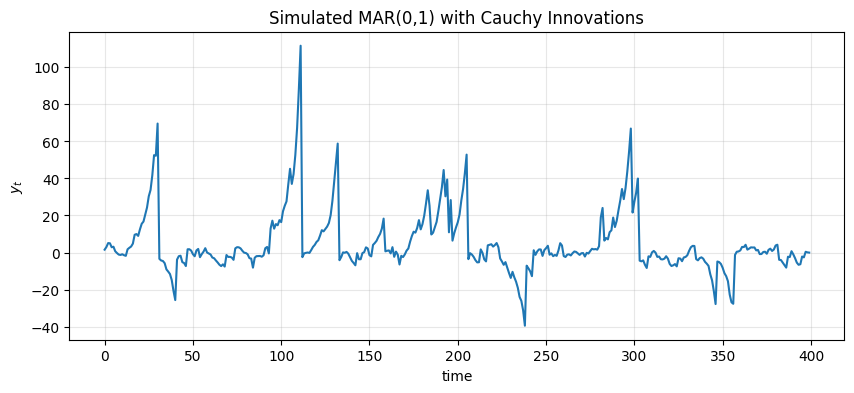

In [120]:
np.random.seed(42)

# Parameters 
T = 400
H = 250
burn = 25
tail_burn = 25
psi = 0.8
sigma = 1.0

N = T + burn + tail_burn

# Generating MAR(0,1) process
eps = sigma * np.random.standard_cauchy(N)
y = np.zeros(N)

for t in range(N - 2, -1, -1):
    y[t] = psi * y[t + 1] + eps[t]

y = y[burn:burn + T]

# Plot time series
plt.figure(figsize=(10, 4))
plt.plot(y)
plt.title("Simulated MAR(0,1) with Cauchy Innovations")
plt.xlabel("time")
plt.ylabel("$y_t$")
plt.grid(True, alpha=0.3)
plt.show()

### Log-Likelihood Function

$$
L_T(\psi,\sigma)
=
\sum_{t=1}^{T-1}
\left[
-\log(\pi)
-\log(\sigma)
-\log\left(
1 + \left(\frac{y_t - \psi y_{t+1}}{\sigma}\right)^2
\right)
\right]
$$

In [121]:
#Log-likelihood Function for MAR(0,1)-Cauchy
def neg_loglik_mar01_cauchy(params, y):

    # params = [psi, sigma]
    psi, sigma = params
    if sigma <= 0 or abs(psi) >= 1:
        return np.inf

    # residuals: eps_t = y_t - psi*y_{t+1}
    eps_hat = y[:-1] - psi * y[1:]

    # Cauchy log-likelihood
    ll = np.sum(
        -np.log(np.pi)
        - np.log(sigma)
        - np.log(1.0 + (eps_hat / sigma) ** 2)
    )

    return -ll


# MLE
psi0 = 0.1
sigma0 = 0.5

# initial guess
x0 = np.array([psi0, sigma0])

# bounds: psi in (-0.99, 0.99), sigma > 0
bounds = [
    (-0.99, 0.99),   # psi
    (1e-6, None)     # sigma
]

res = minimize(
    neg_loglik_mar01_cauchy,
    x0,
    args=(y,),
    method="L-BFGS-B",
    bounds=bounds
)

psi_hat = res.x[0]
sigma_hat = res.x[1]



hess_fun = Hessian(
    lambda th: neg_loglik_mar01_cauchy(th, y),
    method="central",
    step=1e-5
)

Hess = hess_fun(res.x)


Hess = 0.5 * (Hess + Hess.T)
cov = np.linalg.pinv(Hess)
var_diag = np.diag(cov)

if np.any(var_diag < 0):
    print("Warning: negative variance estimates on diagonal; SEs clipped at 0.")


# Extract standard errors
se_psi, se_sigma = np.sqrt(np.diag(cov))

# --- Relative errors ---
rel_psi = (psi_hat - psi) / psi
rel_sigma = (sigma_hat - sigma) / sigma

# Print results 
print("\n=== RESULTS ===")
print(f"psi   = {psi_hat:.4f} (true {psi})   | SE = {se_psi:.4f}   | RelErr = {rel_psi:.2%}")
print(f"sigma = {sigma_hat:.4f} (true {sigma})   | SE = {se_sigma:.4f}   | RelErr = {rel_sigma:.2%}")
print(f"loglik = {-res.fun:.4f} | converged = {res.success}")

# check if eigenvalues are positive and Covariance diagonal is near 0
#print("Eigenvalues:", np.linalg.eigvals(Hess))
#print("diag(cov):", np.diag(cov))


=== RESULTS ===
psi   = 0.7996 (true 0.8)   | SE = 0.0040   | RelErr = -0.05%
sigma = 0.8923 (true 1.0)   | SE = 0.0637   | RelErr = -10.77%
loglik = -956.2739 | converged = True


### Predictive density (closed-form)

$$
l(y_{T+1}\mid y_T)
=
\frac{1}{\pi \sigma}
\frac{\sigma^2}{(y_T-\psi y_{T+1})^2+\sigma^2}
\cdot
\frac{\sigma^2+(1-|\psi|)^2 y_T^2}{\sigma^2+(1-|\psi|)^2 y_{T+1}^2}
$$

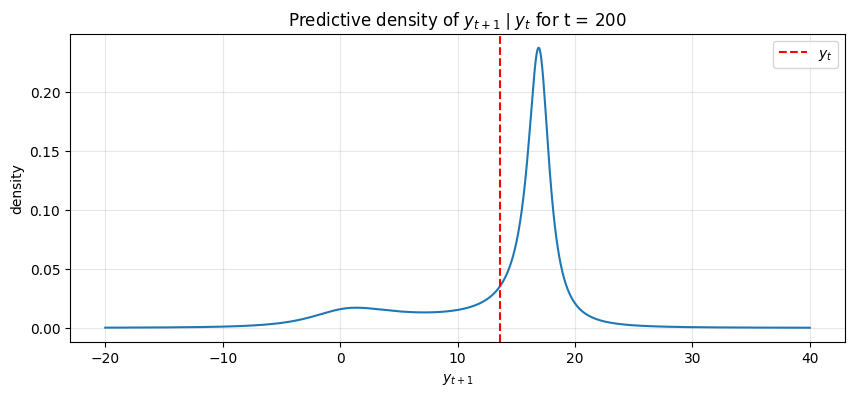

In [122]:
def predictive_density_mar01_cauchy(t0, y_next, y, psi, sigma):
    
    
    # last observed value
    yT = y[t0]

    term1 = 1.0 / (np.pi * sigma)
    term2 = sigma**2 / ((yT - psi * y_next)**2 + sigma**2)
    term3 = (sigma**2 + (1 - abs(psi))**2 * yT**2) / (
        sigma**2 + (1 - abs(psi))**2 * y_next**2
    )
    return term1 * term2 * term3


# grid of candidate values for y_{t+1}
grid = np.linspace(-20, 40, 2000)

# point for which we calculate predictive density
t0 = 199
# compute predictive density using estimated parameters
dens = predictive_density_mar01_cauchy(t0, grid, y, psi_hat, sigma_hat)

area = integrate_area(dens, grid)

if area > 0 and np.isfinite(area):
    dens = dens / area
    
# plot
plt.figure(figsize=(10, 4))
plt.plot(grid, dens)
plt.title(rf"Predictive density of $y_{{t+1}}\mid y_t$ for t = {t0 + 1}")

# Red vertical line at the observed y_t
plt.axvline(
    x=y[t0],
    color="red",
    linestyle="--",
    linewidth=1.5,
    label=rf"$y_t$"
)

plt.xlabel(r"$y_{t+1}$")
plt.ylabel("density")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

### Bimodality Measure

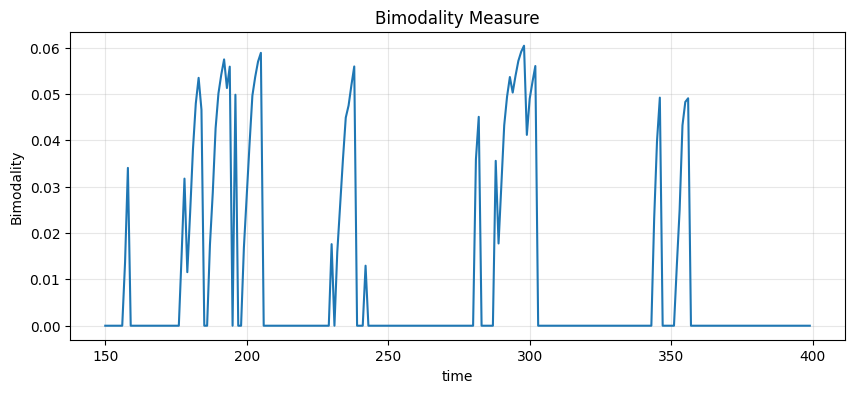

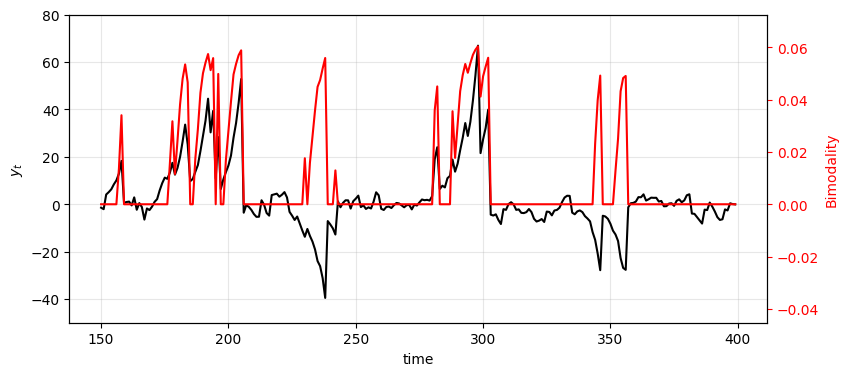

In [123]:
start_t = max(1, T - H)
end_t = T
times = np.arange(start_t, end_t)

bimodality_series = compute_bimodality_series(
    times,
    predictive_density_fn=predictive_density_mar01_cauchy,
    y=y,
    psi=psi_hat,
    sigma=sigma_hat,
    grid_min=-150,
    grid_max=150,
    n_grid= 2000
)

plot_bimodality(times, bimodality_series)

plot_bimodality_and_series(
    times,
    y[start_t:end_t],
    bimodality_series,
    y_limits=(-50, 80)
)


----
# MAR(0,1) with Student-t innovations

### Generate process

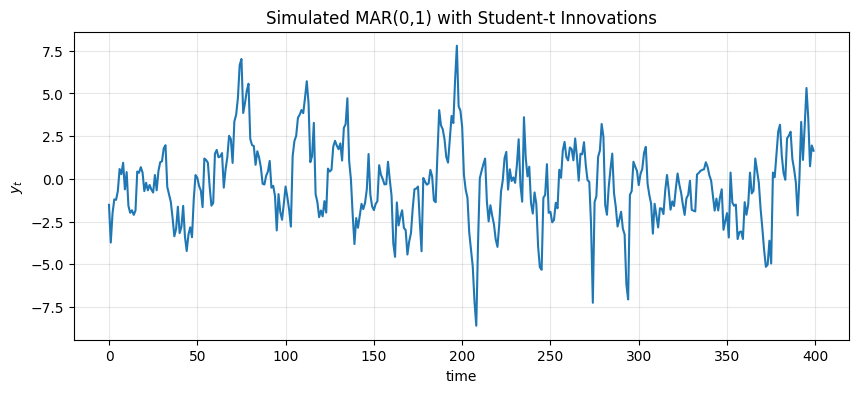

In [124]:
np.random.seed(42)

# Parameters
T = 400
H = 250
burn = 25
tail_burn = 25
psi = 0.8
sigma = 1.0
nu = 3

N = T + burn + tail_burn

# Simulate process
eps = sigma * np.random.standard_t(df=nu, size=N)
y = np.zeros(N)

for t in range(N - 2, -1, -1):
    y[t] = psi * y[t + 1] + eps[t]

# keep the middle T observations
y = y[burn:burn + T]

plt.figure(figsize=(10, 4))
plt.plot(y)
plt.title("Simulated MAR(0,1) with Student-t Innovations")
plt.xlabel("time")
plt.ylabel("$y_t$")
plt.grid(True, alpha=0.3)
plt.show()

### Log-likelihood function

$$
L_T(\psi,\sigma,\nu)
=
\sum_{t=1}^{T-1}
\left[
\log \Gamma\left(\frac{\nu+1}{2}\right)
-
\log \Gamma\left(\frac{\nu}{2}\right)
-
\frac{1}{2}\log(\nu\pi)
-
\log \sigma
-
\frac{\nu+1}{2}
\log\left(
1+\frac{1}{\nu}\left(
\frac{
y_t - \psi y_{t+1}
}{\sigma}
\right)^2
\right)
\right]
$$

In [125]:
# Log-likelihood for MAR(0,1)-Student-t
def neg_loglik_mar01_studentt(params, y):

    #params = [psi, sigma, nu]
    psi, sigma, nu = params

    # residuals: eps_t = y_t - psi*y_{t+1}
    eps_hat = y[:-1] - psi * y[1:]

    # Student-t log-likelihood
    c = (
        gammaln((nu + 1) / 2)
        - gammaln(nu / 2)
        - 0.5 * np.log(nu * np.pi)
        - np.log(sigma)
    )

    ll = np.sum(c - ((nu + 1) / 2) * np.log(1 + (eps_hat / sigma) ** 2 / nu))

    return -ll


# MLE
# Initial values
x0 = np.array([0.2, 1.0, 3.0])   # psi, sigma, nu

# Bounds
bounds = [
    (-0.99, 0.99),   # psi
    (1e-6, None),    # sigma
    (2.01, None)     # nu
]

res = minimize(
    neg_loglik_mar01_studentt,
    x0,
    args=(y,),
    method="L-BFGS-B",
    bounds=bounds
)


psi_hat, sigma_hat, nu_hat = res.x


hess_fun = Hessian(
    lambda th: neg_loglik_mar01_studentt(th, y),
    method="central",
    step=1e-5
)

Hess = hess_fun(res.x)


Hess = 0.5 * (Hess + Hess.T)
cov = np.linalg.pinv(Hess)
var_diag = np.diag(cov)

if np.any(var_diag < 0):
    print("Warning: negative variance estimates on diagonal; SEs clipped at 0.")


# Extract standard errors
se_psi, se_sigma, se_nu = np.sqrt(np.diag(cov))


# --- Relative errors ---
rel_psi = (psi_hat - psi) / psi
rel_sigma = (sigma_hat - sigma) / sigma
rel_nu = (nu_hat - nu) / nu


# --- Print results ---
print("\n=== RESULTS ===")
print(f"psi   = {psi_hat:.4f} (true {psi}) | SE = {se_psi:.4f}   | RelErr = {rel_psi:.2%}")
print(f"sigma = {sigma_hat:.4f} (true {sigma}) | SE = {se_sigma:.4f}    | RelErr = {rel_sigma:.2%}")
print(f"nu    = {nu_hat:.4f} (true {nu})   | SE = {se_nu:.4f}    | RelErr = {rel_nu:.2%}")
print(f"loglik = {-res.fun:.4f} | converged = {res.success}")

# check if eigenvalues are positive and Covariance diagonal is near 0
#print("Eigenvalues:", np.linalg.eigvals(Hess))
#print("diag(cov):", np.diag(cov))


=== RESULTS ===
psi   = 0.7848 (true 0.8) | SE = 0.0240   | RelErr = -1.89%
sigma = 0.9519 (true 1.0) | SE = 0.0636    | RelErr = -4.81%
nu    = 3.2886 (true 3)   | SE = 0.6137    | RelErr = 9.62%
loglik = -675.0493 | converged = True


### Sample-Based Predictive Density

$$
l(y_{T+1}\mid y_T)
=
g(y_T-\psi y_{T+1})
\,
\frac{
\sum_{t=1}^{T} g(y_{T+1}-\psi y_t)
}{
\sum_{t=1}^{T} g(y_T-\psi y_t)
}
$$


$$
g(e)
=
\frac{\Gamma\!\left(\frac{\nu+1}{2}\right)}
{\Gamma\!\left(\frac{\nu}{2}\right)\sqrt{\nu\pi}\,\sigma}
\left(
1+\frac{e^2}{\nu\sigma^2}
\right)^{-\frac{\nu+1}{2}}
$$


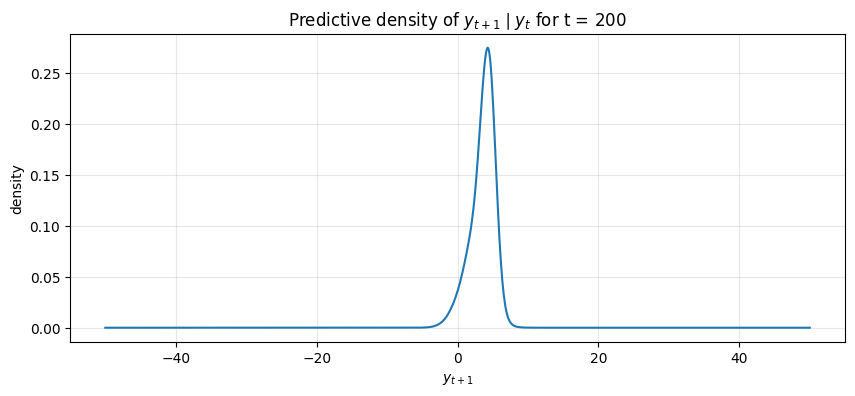

In [126]:
# Sample Based Predictive Density 
def sample_based_pred_density_mar01(t0, y_next, y, psi, sigma, nu):
    y = np.asarray(y)


    yT = y[t0]

    # Historical observations available up to t0
    y_sample = y[:t0+1]

    denom = np.sum(student_t_pdf(yT - psi * y_sample, nu, sigma))
    denom = max(denom, 1e-12)

    dens = np.empty_like(y_next, dtype=float)
    for i, x in enumerate(y_next):
        numer = np.sum(student_t_pdf(x - psi * y_sample, nu, sigma))
        dens[i] = student_t_pdf(yT - psi * x, nu, sigma) * numer / denom

    return dens


# grid of candidate values for y_{t+1}
grid = np.linspace(-50, 50, 1000)

# point for which we calculate predictive density
t0 = 199

dens = sample_based_pred_density_mar01(t0, grid, y, psi_hat, sigma_hat, nu_hat)


# Normalization
area = integrate_area(dens, grid)
if area > 0:
    dens = dens / area

# Plots
plt.figure(figsize=(10, 4))
plt.plot(grid, dens)
plt.title(rf"Predictive density of $y_{{t+1}}\mid y_t$ for t = {t0 + 1}")
plt.xlabel("$y_{t+1}$")
plt.ylabel("density")
plt.grid(alpha=0.3)
plt.show()

### Bimodality Measure

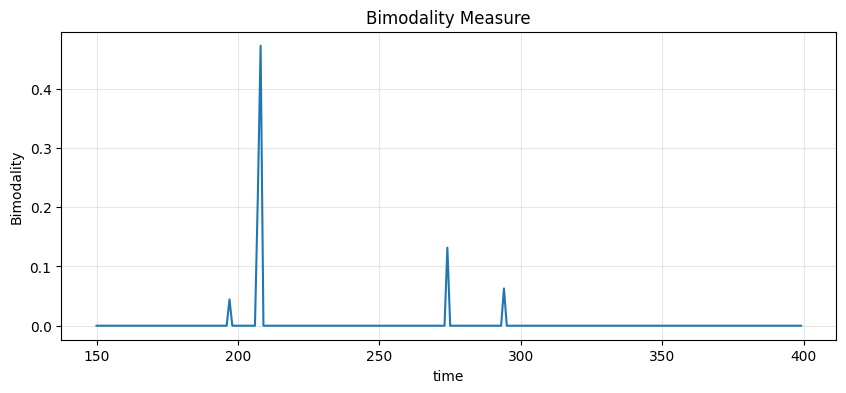

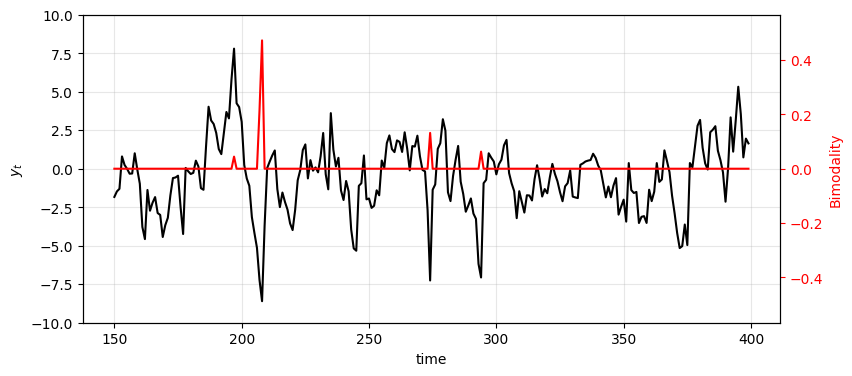

In [127]:
start_t = max(1, T - H)
end_t = T
times = np.arange(start_t, end_t)

bimodality_series = compute_bimodality_series(
    times,
    predictive_density_fn=sample_based_pred_density_mar01,
    y=y,
    psi=psi_hat,
    sigma=sigma_hat,
    nu=nu_hat,
    grid_min=-50,
    grid_max=50,
    n_grid= 1000
)

plot_bimodality(times, bimodality_series)

plot_bimodality_and_series(
    times,
    y[start_t:end_t],
    bimodality_series,
    y_limits=(-10, 10)
)


----
# MAR(1,1) with Cauchy Innovations

### Generate MAR(1,1) process

$$
(1-\phi L)(1-\psi L^{-1})y_t = \varepsilon_t
$$

Using the noncausal component $u_t = (1-\phi L)y_t$:

$$
(1-\psi L^{-1})u_t = \varepsilon_t
\quad\Rightarrow\quad
u_t = \varepsilon_t + \psi u_{t+1}
$$

and then recover $y_t$ from

$$
(1-\phi L)y_t = u_t
\quad\Rightarrow\quad
y_t = u_t + \phi y_{t-1}.
$$

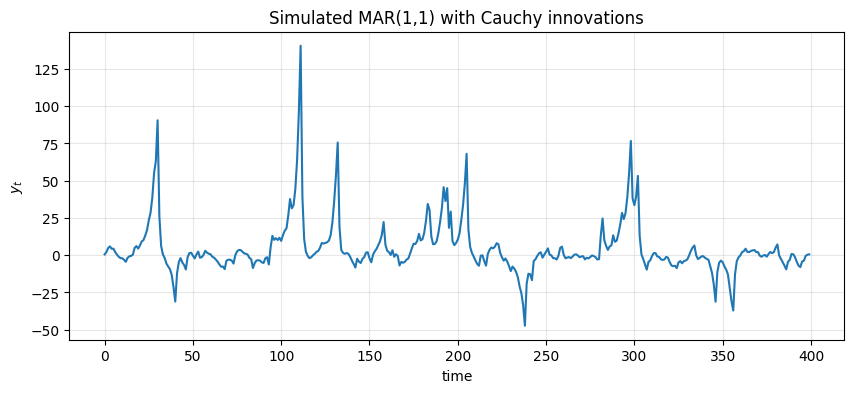

In [128]:
np.random.seed(42)

# Parameters
T = 400
H = 250
burn = 25
extra = 25
N = T + burn + extra

phi = 0.3
psi = 0.7
sigma = 1.0

# Innovation term
eps = sigma * np.random.standard_cauchy(size=N)

# Step 1: noncausal filter
u = np.zeros(N)

for t in range(N - 2, -1, -1):
    u[t] = eps[t] + psi * u[t + 1]

# Step 2: causal filter
y = np.zeros(N)
y[0] = u[0]

for t in range(1, N):
    y[t] = u[t] + phi * y[t - 1]

# Keep the middle part
y = y[burn:burn + T]

# Plot
plt.figure(figsize=(10, 4))
plt.plot(y, lw=1.5)
plt.title("Simulated MAR(1,1) with Cauchy innovations")
plt.xlabel("time")
plt.ylabel(r"$y_t$")
plt.grid(True, alpha=0.3)
plt.show()

### Log-likelihood function

$$
L_T(\phi,\psi,\sigma)
=
\sum_{t=2}^{T-1}
\left[
-\log(\pi\sigma)
-
\log\left(
1+\left(\frac{(1+\phi\psi)y_t
-
\phi y_{t-1}
-
\psi y_{t+1} }{\sigma}\right)^2
\right)
\right].
$$

In [129]:
def neg_loglik_mar11_cauchy(theta, y):
    
    #theta = [phi, psi, sigma]
    phi, psi, sigma = theta

    # residuals e_t
    e = (1 + phi * psi) * y[1:-1] - phi * y[:-2] - psi * y[2:]

    # log-likelihood
    ll = np.sum(- np.log(np.pi * sigma) - np.log(1 + (e / sigma) ** 2))
    return -ll


# Initial values
theta0 = np.array([0.2, 0.2, 1.0])

# Bounds: |phi|<1, |psi|<1, sigma>0
bounds = [(-0.99, 0.99), (-0.99, 0.99), (1e-6, None)]

result = minimize(
    neg_loglik_mar11_cauchy,
    theta0,
    args=(y),
    method="L-BFGS-B",
    bounds=bounds
)


# Extract estimates
phi_hat, psi_hat, sigma_hat = result.x


hess_fun = Hessian(
    lambda th: neg_loglik_mar11_cauchy(th, y),
    method="central",
    step=1e-5
)

Hess = hess_fun(result.x)


Hess = 0.5 * (Hess + Hess.T)
cov = np.linalg.pinv(Hess)
var_diag = np.diag(cov)

if np.any(var_diag < 0):
    print("Warning: negative variance estimates on diagonal; SEs clipped at 0.")


# Extract standard errors
se_phi, se_psi, se_sigma = np.sqrt(np.diag(cov))

# --- Relative errors ---
rel_phi = (phi_hat - phi) / phi
rel_psi = (psi_hat - psi) / psi
rel_sigma = (sigma_hat - sigma) / sigma

# Print results (consistent format)
print("\n=== RESULTS ===")
print(f"phi   = {phi_hat:.4f} (true {phi})   | SE = {se_phi:.4f}   | RelErr = {rel_phi:.2%}")
print(f"psi   = {psi_hat:.4f} (true {psi})   | SE = {se_psi:.4f}   | RelErr = {rel_psi:.2%}")
print(f"sigma = {sigma_hat:.4f} (true {sigma})   | SE = {se_sigma:.4f}   | RelErr = {rel_sigma:.2%}")
print(f"loglik = {-result.fun:.4f} | converged = {result.success}")

# check if eigenvalues are positive and Covariance diagonal is near 0
#print("Eigenvalues:", np.linalg.eigvals(Hess))
#print("diag(cov):", np.diag(cov)) 


=== RESULTS ===
phi   = 0.2920 (true 0.3)   | SE = 0.0081   | RelErr = -2.66%
psi   = 0.6995 (true 0.7)   | SE = 0.0053   | RelErr = -0.08%
sigma = 0.8958 (true 1.0)   | SE = 0.0642   | RelErr = -10.42%
loglik = -954.0052 | converged = True


### Predictive Density

$$
l(y_{T+1}\mid y_T)
=
\frac{1}{\pi \sigma}
\frac{\sigma^2}{(u_T-\psi (y_{T+1}-\phi y_T))^2+\sigma^2}
\cdot
\frac{\sigma^2+(1-|\psi|)^2 u_T^2}{\sigma^2+(1-|\psi|)^2 (y_{T+1} - \phi y_T)^2}
$$

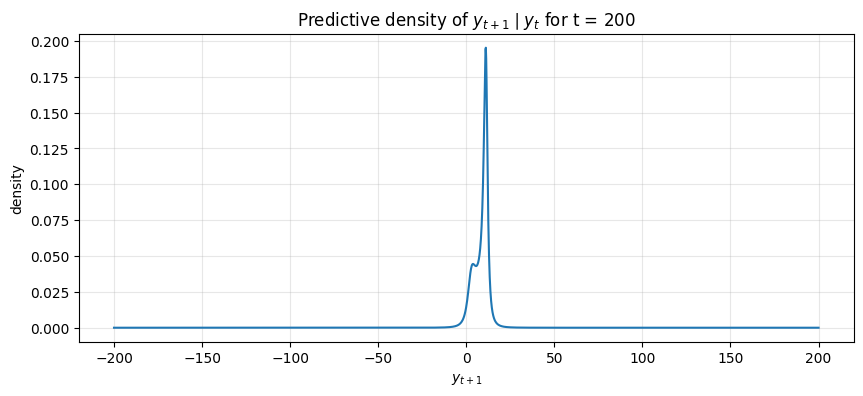

In [130]:
# Predictive Density
def predictive_density_mar11_cauchy(t0, y_next, y, phi, psi, sigma):

    y = np.asarray(y, dtype=float)
    y_next = np.asarray(y_next, dtype=float)

    y_T = y[t0]
    y_Tm1 = y[t0-1]
 
    # compute u_T (u_T = y_T - phi * y_{T-1})
    u_T = y_T - phi * y_Tm1

    # compute u_{T+1}: z = y_{T+1} - phi * y_{T}
    z = y_next - phi * y_T

    term1 = 1.0 / (np.pi * sigma)
    term2 = sigma**2 / ((u_T - psi * z)**2 + sigma**2)
    term3 = (sigma**2 + (1 - abs(psi))**2 * u_T**2) / (
        sigma**2 + (1 - abs(psi))**2 * z**2
    )

    density = term1 * term2 * term3

    return density



# grid of candidate values for y_{t+1}
grid = np.linspace(-200, 200, 2000)

# point for which we calculate predictive density
t0 = 199

dens = predictive_density_mar11_cauchy(t0, grid, y, phi_hat, psi_hat, sigma_hat)

area = integrate_area(dens, grid)
if area > 0 and np.isfinite(area):
    dens = dens / area

# plot
plt.figure(figsize=(10, 4))
plt.plot(grid, dens)
plt.title(rf"Predictive density of $y_{{t+1}}\mid y_t$ for t = {t0 + 1}")
plt.xlabel(r"$y_{t+1}$")
plt.ylabel("density")
plt.grid(True, alpha=0.3)
plt.show()

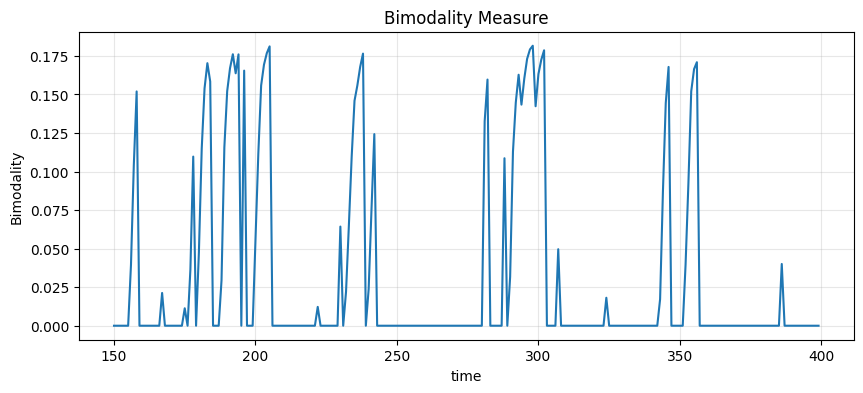

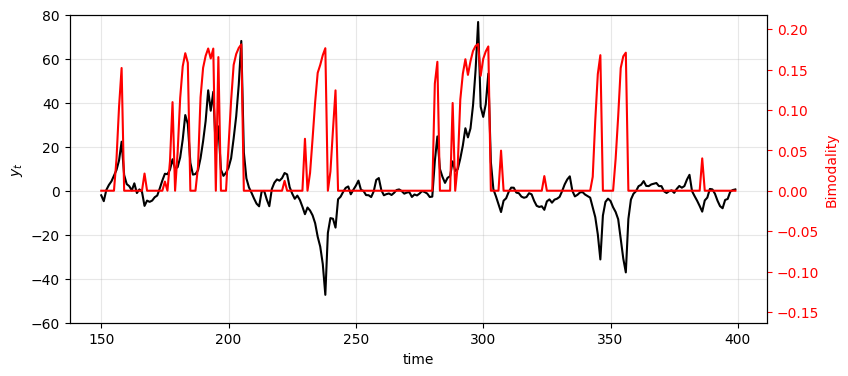

In [131]:
start_t = max(1, T - H)
end_t = T
times = np.arange(start_t, end_t)

bimodality_series = compute_bimodality_series(
    times,
    predictive_density_fn=predictive_density_mar11_cauchy,
    y=y,
    phi=phi_hat,
    psi=psi_hat,
    sigma=sigma_hat,
    grid_min=-200,
    grid_max=200,
    n_grid= 2000
)

plot_bimodality(times, bimodality_series)

plot_bimodality_and_series(
    times,
    y[start_t:end_t],
    bimodality_series,
    y_limits=(-60, 80)
)

----
# MAR(1,1) with Student-t innovations

### Generate Process

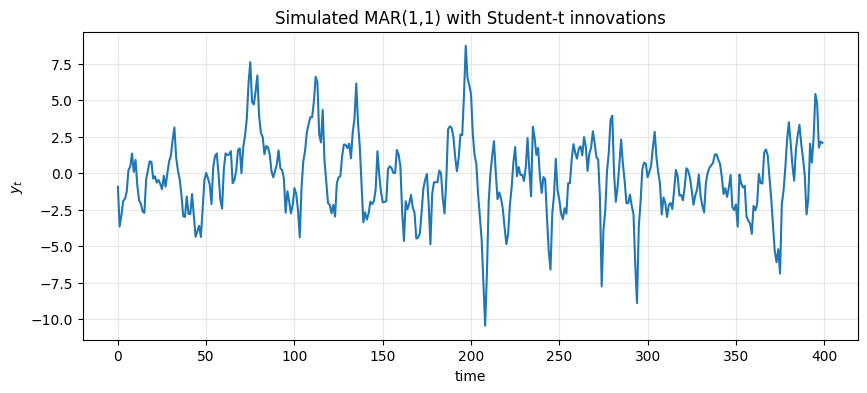

In [132]:
np.random.seed(42)

# Parameters
T = 400
H = 250
burn = 25
extra = 25
N = T + burn + extra

phi = 0.3
psi = 0.7
sigma = 1.0
nu = 3 

# Innovation term
eps = sigma * np.random.standard_t(df=nu, size=N)

# Step 1: noncausal filter
u = np.zeros(N)

for t in range(N - 2, -1, -1):
    u[t] = eps[t] + psi * u[t + 1]

# Step 2: causal filter
y = np.zeros(N)
y[0] = u[0]

for t in range(1, N):
    y[t] = u[t] + phi * y[t - 1]

# Keep the middle part
y = y[burn:burn + T]

# Plot
plt.figure(figsize=(10, 4))
plt.plot(y, lw=1.5)
plt.title("Simulated MAR(1,1) with Student-t innovations")
plt.xlabel("time")
plt.ylabel(r"$y_t$")
plt.grid(True, alpha=0.3)
plt.show()

### Log-likelihood function

$$
L_T(\phi,\psi,\sigma,\nu)
=
\sum_{t=2}^{T-1}
\left[
\log \Gamma\left(\frac{\nu+1}{2}\right)
-
\log \Gamma\left(\frac{\nu}{2}\right)
-
\frac{1}{2}\log(\nu\pi)
-
\log \sigma
-
\frac{\nu+1}{2}
\log\left(
1+\frac{1}{\nu}\left(
\frac{
(1+\phi\psi)y_t
-
\phi y_{t-1}
-
\psi y_{t+1}
}{\sigma}
\right)^2
\right)
\right].
$$

In [133]:
def neg_loglik_mar11_studentt(theta, y):
    # theta = [phi, psi, sigma, nu]
    phi, psi, sigma, nu = theta

    # residuals
    e = (1 + phi * psi) * y[1:-1] - phi * y[:-2] - psi * y[2:]

    # Student-t log-likelihood
    c = (
        gammaln((nu + 1) / 2)
        - gammaln(nu / 2)
        - 0.5 * np.log(nu * np.pi)
        - np.log(sigma)
    )

    ll = np.sum(c - ((nu + 1) / 2) * np.log(1 + (e / sigma) ** 2 / nu))

    return -ll


# Initial values
theta0 = np.array([0.2, 0.2, 1.0, 5.0])   # phi, psi, sigma, nu

# Bounds
bounds = [
    (-0.99, 0.99),   # phi
    (-0.99, 0.99),   # psi
    (1e-6, None),    # sigma
    (2.01, None)  # nu
]

result = minimize(
    neg_loglik_mar11_studentt,
    theta0,
    args=(y),
    method="L-BFGS-B",
    bounds=bounds
)

# Extract estimates
phi_hat, psi_hat, sigma_hat, nu_hat = result.x


hess_fun = Hessian(
    lambda th: neg_loglik_mar11_studentt(th, y),
    method="central",
    step=1e-5
)

Hess = hess_fun(result.x)


Hess = 0.5 * (Hess + Hess.T)
cov = np.linalg.pinv(Hess)
var_diag = np.diag(cov)

if np.any(var_diag < 0):
    print("Warning: negative variance estimates on diagonal; SEs clipped at 0.")
 

# Extract standard errors
se_phi, se_psi, se_sigma, se_nu = np.sqrt(np.diag(cov))

# --- Relative errors ---
rel_phi = (phi_hat - phi) / phi
rel_psi = (psi_hat - psi) / psi
rel_sigma = (sigma_hat - sigma) / sigma
rel_nu = (nu_hat - nu) / nu

# Print results (consistent format)
print("\n=== RESULTS ===")
print(f"phi   = {phi_hat:.4f} (true {phi})   | SE = {se_phi:.4f}   | RelErr = {rel_phi:.2%}")
print(f"psi   = {psi_hat:.4f} (true {psi})   | SE = {se_psi:.4f}   | RelErr = {rel_psi:.2%}")
print(f"sigma = {sigma_hat:.4f} (true {sigma})   | SE = {se_sigma:.4f}   | RelErr = {rel_sigma:.2%}")
print(f"nu    = {nu_hat:.4f} (true {nu})     | SE = {se_nu:.4f}   | RelErr = {rel_nu:.2%}")
print(f"loglik = {-result.fun:.4f} | converged = {result.success}")

# check if eigenvalues are positive and Covariance diagonal is near 0
#print("Eigenvalues:", np.linalg.eigvals(Hess))
#print("diag(cov):", np.diag(cov))


=== RESULTS ===
phi   = 0.3865 (true 0.3)   | SE = 0.0437   | RelErr = 28.83%
psi   = 0.6498 (true 0.7)   | SE = 0.0377   | RelErr = -7.18%
sigma = 0.9388 (true 1.0)   | SE = 0.0631   | RelErr = -6.12%
nu    = 3.2109 (true 3)     | SE = 0.5907   | RelErr = 7.03%
loglik = -671.0522 | converged = True


### Sample-Based Predictive Density

$$
l(u_{T+1}\mid u_T)
=
g(u_T-\psi u_{T+1})
\,
\frac{
\sum_{t=1}^{T} g(u_{T+1}-\psi u_t)
}{
\sum_{t=1}^{T} g(u_T-\psi u_t)
}
$$

$$
l(y_{T+1}\mid y_T)=

g\left(u_T-\psi (y_{T+1}-\phi y_T)\right)
\cdot
\frac{
\sum_{t=1}^{T} g\left((y_{T+1}-\phi y_T)-\psi u_t\right)
}{
\sum_{t=1}^{T} g\left(u_T-\psi u_t\right)
}
$$

$$
g(e)
=
\frac{\Gamma\!\left(\frac{\nu+1}{2}\right)}
{\Gamma\!\left(\frac{\nu}{2}\right)\sqrt{\nu\pi}\,\sigma}
\left(
1+\frac{e^2}{\nu\sigma^2}
\right)^{-\frac{\nu+1}{2}}
$$

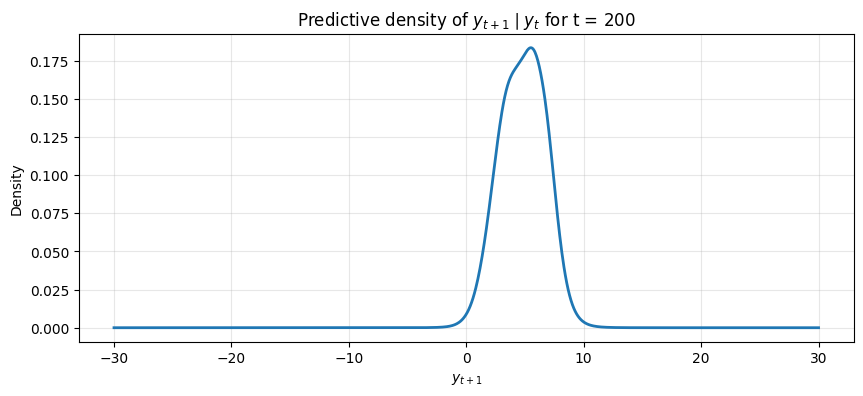

In [134]:
# Sample Based Predictive Density
def sample_based_pred_density_mar11(t0,y_next,y,phi,psi,sigma,nu,):

    y = np.asarray(y, dtype=float)
    y_next = np.asarray(y_next, dtype=float)

    y_T = y[t0]
    y_Tm1 = y[t0-1]

    # current state u_T
    u_T = y_T - phi * y_Tm1

    # sample of past states u_t = y_t - phi y_{t-1}, for t = 1,...,T-1 (in 0-based indexing)
    u_sample = y[1:t0+1] - phi * y[:t0]

    # candidate future state
    u_next = y_next - phi * y_T

    # first factor: g(u_T - psi*u_{T+1})
    term1 = student_t_pdf(u_T - psi * u_next, nu, sigma)

    # numerator: sum_t g(u_{T+1} - psi*u_t)
    num = np.sum(student_t_pdf(u_next[:, None] - psi * u_sample[None, :], nu, sigma), axis=1 )

    # denominator: sum_t g(u_T - psi*u_t)
    den = np.sum(student_t_pdf(u_T - psi * u_sample, nu, sigma))
    den = max(den, 1e-12)

    dens = term1 * (num / den)

    return dens


grid = np.linspace(-30, 30, 1000)

# point for which we calculate predictive density
t0 = 199

dens = sample_based_pred_density_mar11(t0, grid, y, phi_hat, psi_hat, sigma_hat, nu_hat)

# normalization
area = integrate_area(dens, grid)
if area > 0 and np.isfinite(area):
    dens = dens / area

# Plot
plt.figure(figsize=(10, 4))
plt.plot(grid, dens, lw=2)
plt.title(rf"Predictive density of $y_{{t+1}}\mid y_t$ for t = {t0 + 1}")
plt.xlabel(r"$y_{t+1}$")
plt.ylabel("Density")
plt.grid(True, alpha=0.3)
plt.show()

### Bimodality Measure

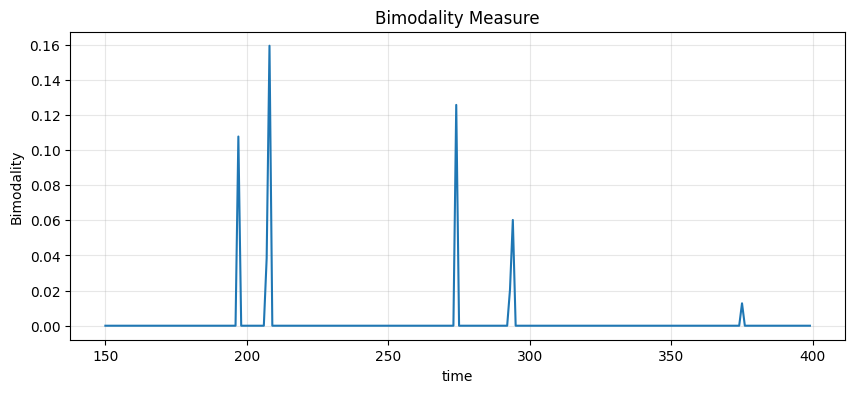

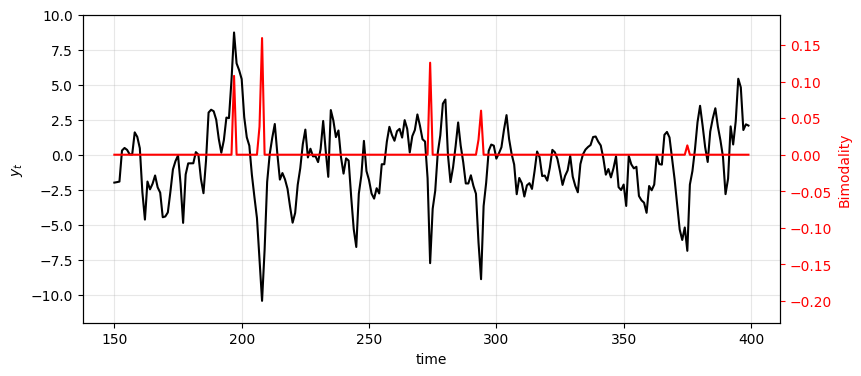

In [135]:
start_t = max(1, T - H)
end_t = T
times = np.arange(start_t, end_t)

bimodality_series = compute_bimodality_series(
    times,
    predictive_density_fn=sample_based_pred_density_mar11,
    y=y,
    phi=phi_hat,
    psi=psi_hat,
    sigma=sigma_hat,
    nu=nu_hat,
    grid_min=-30,
    grid_max=30,
    n_grid= 1000
)

plot_bimodality(times, bimodality_series)

plot_bimodality_and_series(
    times,
    y[start_t:end_t],
    bimodality_series,
    y_limits=(-12, 10)
)

----
# MARX(1,1,1) with Cauchy innovations

### Generate MARX(1,1,1) process

$$
(1-\phi L)(1-\psi L^{-1})y_t = z_t
$$

with

$$
z_t = \beta X_t + \varepsilon_t
$$


Using the noncausal component $u_t = (1-\phi L)y_t$:

$$
(1-\psi L^{-1})u_t = z_t
\quad\Rightarrow\quad
u_t = z_t + \psi u_{t+1}
$$

and then recover $y_t$ from

$$
(1-\phi L)y_t = u_t
\quad\Rightarrow\quad
y_t = u_t + \phi y_{t-1}.
$$

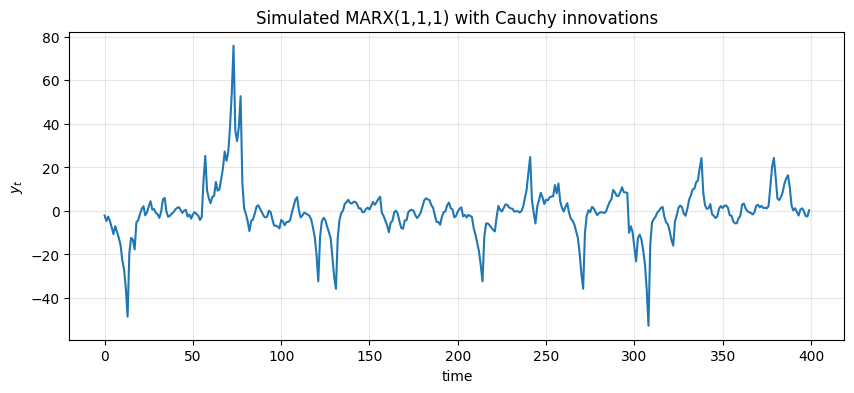

In [136]:
np.random.seed(42)

# Parameters
T = 400
H = 250
burn = 25
extra = 25
N = T + burn + extra

phi = 0.3
psi = 0.7
beta = 0.6
sigma = 1.0

# Exogenous regressor (Normal Distribution)
X = np.random.normal(loc=0.0, scale=1.0, size=N)

"""
# Simulate Exogenous regressor as AR(1) Process
rho = 0.8          # persistence
sigma_eta = 1.0    # innovation std

X = np.zeros(N)
eta = np.random.normal(0.0, sigma_eta, size=N)

for t in range(1, N):
    X[t] = rho * X[t-1] + eta[t]
"""

# Innovation term
eps = sigma * np.random.standard_cauchy(size=N)

# Combined shock
z = beta * X + eps

# Step 1: noncausal filter
u = np.zeros(N)
for t in range(N - 2, -1, -1):
    u[t] = z[t] + psi * u[t + 1]

# Step 2: causal filter
y = np.zeros(N)
y[0] = u[0]
for t in range(1, N):
    y[t] = u[t] + phi * y[t - 1]

# Keep the middle part
y = y[burn:burn + T]
X = X[burn:burn + T]

# Plot
plt.figure(figsize=(10, 4))
plt.plot(y, lw=1.5)
plt.title("Simulated MARX(1,1,1) with Cauchy innovations")
plt.xlabel("time")
plt.ylabel(r"$y_t$")
plt.grid(True, alpha=0.3)
plt.show()

### Log-likelihood function

$$
L_T(\phi,\psi,\beta,\sigma)
=
\sum_{t=2}^{T-1}
\left[
-\log(\pi\sigma)
-
\log\left(
1+\left(\frac{(1+\phi\psi)y_t
-
\phi y_{t-1}
-
\psi y_{t+1}
-
\beta X_t}{\sigma}\right)^2
\right)
\right].
$$

In [137]:
def neg_loglik_marx111_cauchy(theta, y, X):
    
    #theta = [phi, psi, beta, sigma]
    phi, psi, beta, sigma = theta

    # residuals e_t
    e = (1 + phi * psi) * y[1:-1] - phi * y[:-2] - psi * y[2:] - beta * X[1:-1]

    # log-likelihood
    ll = np.sum(- np.log(np.pi * sigma) - np.log(1 + (e / sigma) ** 2))
    return -ll


# Initial values
theta0 = np.array([0.2, 0.2, 0.1, 1.0])

# Bounds: |phi|<1, |psi|<1, sigma>0
bounds = [(-0.99, 0.99), (-0.99, 0.99), (None, None), (1e-6, None)]

result = minimize(
    neg_loglik_marx111_cauchy,
    theta0,
    args=(y, X),
    method="L-BFGS-B",
    bounds=bounds
)


# Extract estimates
phi_hat, psi_hat, beta_hat, sigma_hat = result.x


hess_fun = Hessian(
    lambda th: neg_loglik_marx111_cauchy(th, y, X),
    method="central",
    step=1e-5
)

Hess = hess_fun(result.x)


Hess = 0.5 * (Hess + Hess.T)
cov = np.linalg.pinv(Hess)
var_diag = np.diag(cov)

if np.any(var_diag < 0):
    print("Warning: negative variance estimates on diagonal; SEs clipped at 0.")


# Extract standard errors
se_phi, se_psi, se_beta, se_sigma = np.sqrt(np.diag(cov))

# --- Relative errors ---
rel_phi = (phi_hat - phi) / phi
rel_psi = (psi_hat - psi) / psi
rel_beta = (beta_hat - beta) / beta
rel_sigma = (sigma_hat - sigma) / sigma

# Print results (consistent format)
print("\n=== RESULTS ===")
print(f"phi   = {phi_hat:.4f} (true {phi})   | SE = {se_phi:.4f}   | RelErr = {rel_phi:.2%}")
print(f"psi   = {psi_hat:.4f} (true {psi})   | SE = {se_psi:.4f}   | RelErr = {rel_psi:.2%}")
print(f"beta  = {beta_hat:.4f} (true {beta})   | SE = {se_beta:.4f}   | RelErr = {rel_beta:.2%}")
print(f"sigma = {sigma_hat:.4f} (true {sigma})   | SE = {se_sigma:.4f}   | RelErr = {rel_sigma:.2%}")
print(f"loglik = {-result.fun:.4f} | converged = {result.success}")

# check if eigenvalues are positive and Covariance diagonal is near 0
#print("Eigenvalues:", np.linalg.eigvals(Hess))
#print("diag(cov):", np.diag(cov)) 


=== RESULTS ===
phi   = 0.3031 (true 0.3)   | SE = 0.0075   | RelErr = 1.03%
psi   = 0.7125 (true 0.7)   | SE = 0.0064   | RelErr = 1.79%
beta  = 0.7275 (true 0.6)   | SE = 0.0597   | RelErr = 21.24%
sigma = 0.8329 (true 1.0)   | SE = 0.0584   | RelErr = -16.71%
loglik = -897.9684 | converged = True


### Predictive Density

$$
\begin{aligned}
l(y_{T+1}\mid u_T,\mathbf{X}_{T:\infty})
&=
\frac{1}{\pi\sigma}
\frac{\sigma^2}
{\left[u_T-\psi(y_{T+1}-\phi y_T)-\boldsymbol{\beta}\mathbf{X}_T\right]^2+\sigma^2}
\\[6pt]
&\quad\times
\frac{
\sigma^2+(1-|\psi|)^2
\left[
u_T-\boldsymbol{\beta}\sum_{j=0}^{\infty}\psi^j\mathbf{X}_{T+j}
\right]^2
}{
\sigma^2+(1-|\psi|)^2
\left[
(y_{T+1}-\phi y_T)-\boldsymbol{\beta}\sum_{j=0}^{\infty}\psi^j\mathbf{X}_{T+1+j}
\right]^2
}.
\end{aligned}
$$

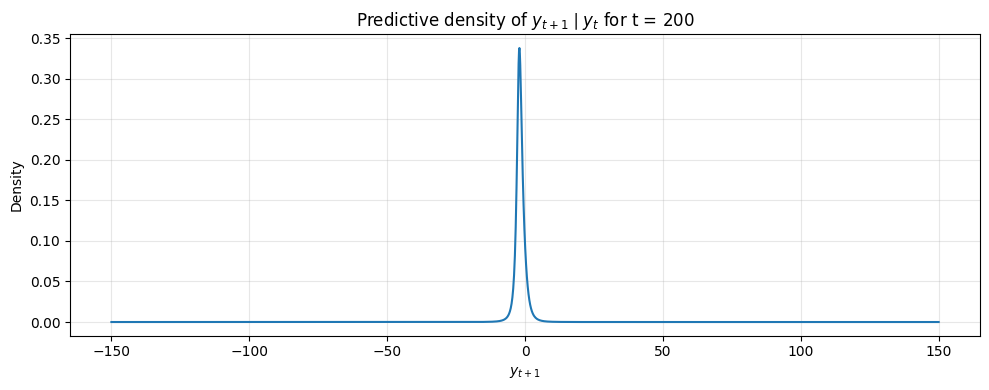

In [138]:
def predictive_density_marx111_cauchy(t0, y_next, y, X,
                                        phi, psi, beta, sigma):

    y = np.asarray(y, dtype=float)
    X = np.asarray(X, dtype=float)
    y_next = np.asarray(y_next, dtype=float)
    beta = np.atleast_1d(np.asarray(beta, dtype=float))

    if X.ndim == 1:
        X = X.reshape(-1, 1)

    if len(X) != len(y):
        raise ValueError("X and y must have the same number of rows.")
    if X.shape[1] != len(beta):
        raise ValueError("beta must match the number of columns in X.")
    if not (1 <= t0 < len(y)):
        raise ValueError("t0 must satisfy 1 <= t0 < len(y).")
    if abs(psi) >= 1:
        raise ValueError("|psi| must be less than 1.")
    if sigma <= 0:
        raise ValueError("sigma must be positive.")

    T = len(y) - 1

    # Observed values at t0
    y_T = y[t0]
    y_Tm1 = y[t0 - 1]

    # Compute u_t
    u_T = y_T - phi * y_Tm1

    # Candidate u_{t+1}
    z = y_next - phi * y_T

    # Exogenous contribution beta'X_t
    bX = X @ beta

    # --------------------------------------
    # EXOGENOUS SUMS
    # --------------------------------------

    if t0 < T:
        # IN-SAMPLE:
        # Use realised X values only, up to T.
        # Truncate the sums at T.

        m_t = sum(
            psi**j * bX[t0 + j]
            for j in range(T - t0 + 1)
        )

        m_tp1 = sum(
            psi**j * bX[t0 + 1 + j]
            for j in range(T - t0)
        )

    else:
        # OUT-OF-SAMPLE:
        # Assume X[T+j] = 0 for all j >= 1.
        # Keep actual observed X[T].

        m_t = bX[T]
        m_tp1 = 0.0

    # --------------------------------------
    # CAUCHY PREDICTIVE DENSITY
    # --------------------------------------

    # First term: Cauchy normalization
    term1 = 1.0 / (np.pi * sigma)

    # Second term: innovation density
    term2 = sigma**2 / (
        (u_T - psi * z - bX[t0])**2 + sigma**2
    )

    # Third term: conditional marginal-density ratio
    a = (1.0 - abs(psi))**2

    term3 = (
        sigma**2 + a * (u_T - m_t)**2
    ) / (
        sigma**2 + a * (z - m_tp1)**2
    )

    density = term1 * term2 * term3

    return density


# --------------------------------------
# PREDICTIVE DENSITY EVALUATION
# --------------------------------------

# Grid of candidate values for y_{t+1}
grid = np.linspace(-150, 150, 2000)

# Choose prediction period
t0 = 199

dens = predictive_density_marx111_cauchy(
    t0, grid, y, X,
    phi_hat, psi_hat, beta_hat, sigma_hat
)

# Normalize over the numerical grid
area = np.trapezoid(dens, grid)

if area > 0 and np.isfinite(area):
    dens = dens / area

# --------------------------------------
# PLOT
# --------------------------------------

plt.figure(figsize=(10, 4))
plt.plot(grid, dens)

plt.title(
    rf"Predictive density of $y_{{t+1}}\mid y_t$ "
    rf"for t = {t0 + 1}"
)

plt.xlabel(r"$y_{t+1}$")
plt.ylabel("Density")

plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()



### Bimodality Measure

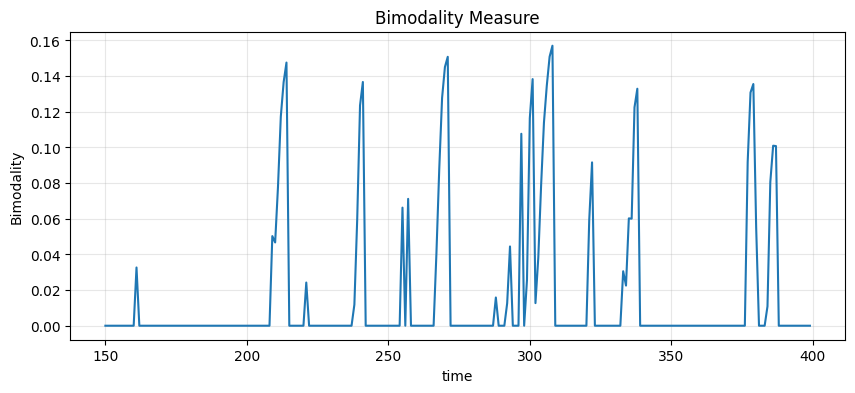

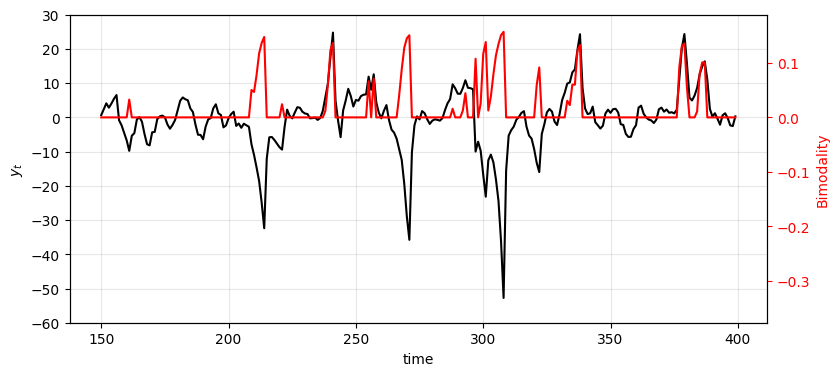

In [139]:
start_t = max(1, T - H)
end_t = T
times = np.arange(start_t, end_t)

bimodality_series = compute_bimodality_series(
    times,
    predictive_density_fn=predictive_density_marx111_cauchy,
    y=y,
    X=X,
    phi=phi_hat,
    psi=psi_hat,
    beta=beta_hat,
    sigma=sigma_hat,
    grid_min=-150,
    grid_max=150,
    n_grid= 2000
)

plot_bimodality(times, bimodality_series)

plot_bimodality_and_series(
    times,
    y[start_t:end_t],
    bimodality_series,
    y_limits=(-60, 30)
)

### Sample-Based Predictive Density

$$
g(e)
=
\frac{1}
{\pi \gamma\!\left(1 + \left(\frac{e}{\gamma} \right)^2 \right)}
$$


$$
\hat l(u_{T+1}\mid u_T, X_T)
=
g(u_T-\psi u_{T+1} - \beta X_T)
\,
\frac{
\sum_{t=1}^{T} g(u_{T+1}-\psi u_t - \beta X_{T+1})
}{
\sum_{t=1}^{T} g(u_T-\psi u_t - \beta X_T)
}
$$

$$
\hat l(y_{T+1}\mid y_T,X_T)=

g\left(u_T-\psi (y_{T+1}-\phi y_T)-\beta X_T\right)
\cdot
\frac{
\sum_{t=1}^{T} g\left((y_{T+1}-\phi y_T)-\psi u_t - \beta X_{T+1} \right)
}{
\sum_{t=1}^{T} g\left(u_T-\psi u_t-\beta X_T\right)
}
$$

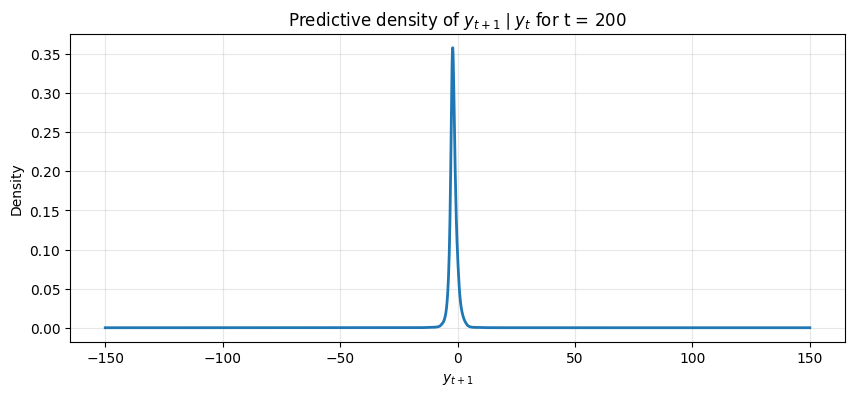

In [140]:

# Cauchy PDF
def cauchy_density(e, sigma):
    return 1 / (np.pi * sigma * (1 + (e / sigma)**2))


def marx_cauchy_sample_based_pred_density(
    t0, y_next, y, X, phi, psi, beta, sigma
):
    y = np.asarray(y, dtype=float)
    X = np.asarray(X, dtype=float)
    y_next = np.asarray(y_next, dtype=float)

    # Current and next exogenous observations
    x_T = X[t0]
    x_next = X[t0 + 1] if t0 + 1 < len(X) else 0.0


    # Current state
    y_T = y[t0]
    y_Tm1 = y[t0 - 1]
    u_T = y_T - phi * y_Tm1

    # Historical states
    u_sample = y[1:t0+1] - phi * y[:t0]

    # Candidate future state
    u_next = y_next - phi * y_T

    # First factor
    term1 = cauchy_density(
        u_T - psi * u_next - beta * x_T,
        sigma
    )

    # Numerator (including x_next)
    num = np.sum(
        cauchy_density(
            u_next[:, None]
            - psi * u_sample[None, :]
            - beta * x_next,
            sigma
        ),
        axis=1
    )

    # Denominator
    den = np.sum(
        cauchy_density(
            u_T - psi * u_sample - beta * x_T,
            sigma
        )
    )
    den = max(den, 1e-12)

    return term1 * (num / den)


# Prediction grid
grid = np.linspace(-150, 150, 2000)

# Point for which we calculate predictive density
t0 = 199

dens = marx_cauchy_sample_based_pred_density(
    t0, grid, y, X,
    phi_hat, psi_hat, beta_hat, sigma_hat
)

# Normalization
area = integrate_area(dens, grid)
if area > 0 and np.isfinite(area):
    dens = dens / area

# Plot
plt.figure(figsize=(10, 4))
plt.plot(grid, dens, lw=2)
plt.title(
    rf"Predictive density of $y_{{t+1}}\mid y_t$ for t = {t0 + 1}"
)
plt.xlabel(r"$y_{t+1}$")
plt.ylabel("Density")
plt.grid(True, alpha=0.3)
plt.show()


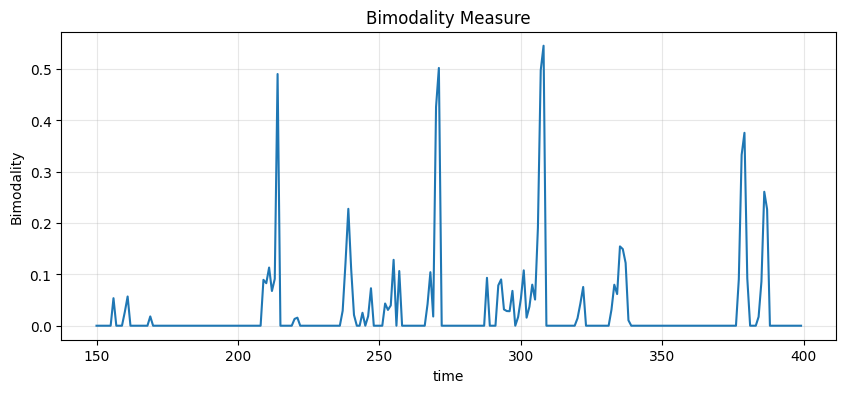

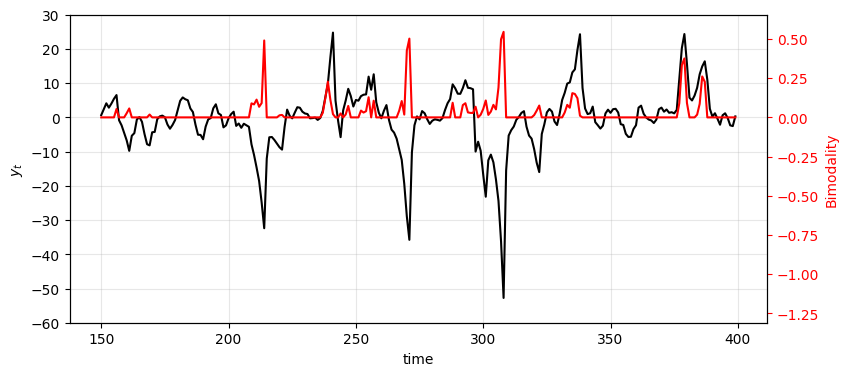

In [141]:
start_t = max(1, T - H)
end_t = T
times = np.arange(start_t, end_t)

bimodality_series = compute_bimodality_series(
    times,
    predictive_density_fn=marx_cauchy_sample_based_pred_density,
    y=y,
    X=X,
    phi=phi_hat,
    psi=psi_hat,
    beta=beta_hat,
    sigma=sigma_hat,
    grid_min=-150,
    grid_max=150,
    n_grid= 2000
)

plot_bimodality(times, bimodality_series)

plot_bimodality_and_series(
    times,
    y[start_t:end_t],
    bimodality_series,
    y_limits=(-60, 30)
)

----
# MARX(1,1,1) with Student-t innovations

### Generate Process

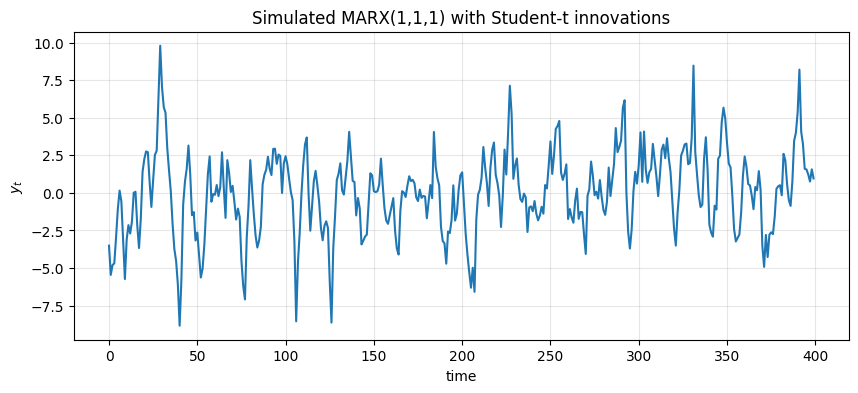

In [142]:
np.random.seed(42)

# Parameters
T = 400
H = 250
burn = 25
extra = 25
N = T + burn + extra

phi = 0.3
psi = 0.7
beta = 0.6
sigma = 1.0
nu = 3 

# Exogenous regressor
X = np.random.normal(loc=0.0, scale=1.0, size=N)

# Student-t innovations
eps = sigma * np.random.standard_t(df=nu, size=N)

# Combined shock
z = beta * X + eps

# Step 1: noncausal filter
u = np.zeros(N)
for t in range(N - 2, -1, -1):
    u[t] = z[t] + psi * u[t + 1]

# Step 2: causal filter
y = np.zeros(N)
y[0] = u[0]
for t in range(1, N):
    y[t] = u[t] + phi * y[t - 1]

# Keep the middle part
y = y[burn:burn + T]
X = X[burn:burn + T]

plt.figure(figsize=(10, 4))
plt.plot(y, lw=1.5)
plt.title("Simulated MARX(1,1,1) with Student-t innovations")
plt.xlabel("time")
plt.ylabel(r"$y_t$")
plt.grid(True, alpha=0.3)
plt.show()

### Log-likelihood function

$$
L_T(\phi,\psi,\beta,\sigma,\nu)
=
\sum_{t=2}^{T-1}
\left[
\log \Gamma\left(\frac{\nu+1}{2}\right)
-
\log \Gamma\left(\frac{\nu}{2}\right)
-
\frac{1}{2}\log(\nu\pi)
-
\log \sigma
-
\frac{\nu+1}{2}
\log\left(
1+\frac{1}{\nu}\left(
\frac{
(1+\phi\psi)y_t
-
\phi y_{t-1}
-
\psi y_{t+1}
-
\beta X_t
}{\sigma}
\right)^2
\right)
\right].
$$

In [143]:
def neg_loglik_marx111_studentt(theta, y, X):
    # theta = [phi, psi, beta, sigma, nu]
    phi, psi, beta, sigma, nu = theta

    # residuals
    e = (1 + phi * psi) * y[1:-1] - phi * y[:-2] - psi * y[2:] - beta * X[1:-1]

    # Student-t log-likelihood
    c = (
        gammaln((nu + 1) / 2)
        - gammaln(nu / 2)
        - 0.5 * np.log(nu * np.pi)
        - np.log(sigma)
    )

    ll = np.sum(c - ((nu + 1) / 2) * np.log(1 + (e / sigma) ** 2 / nu))

    return -ll


# Initial values
theta0 = np.array([0.2, 0.2, 0.7, 1.0, 5.0])   # phi, psi, beta, sigma, nu

# Bounds
bounds = [
    (-0.99, 0.99),   # phi
    (-0.99, 0.99),   # psi
    (None, None),    # beta
    (1e-6, None),    # sigma
    (2.01, None)  # nu
]

result = minimize(
    neg_loglik_marx111_studentt,
    theta0,
    args=(y, X),
    method="L-BFGS-B",
    bounds=bounds
)

# Extract estimates
phi_hat, psi_hat, beta_hat, sigma_hat, nu_hat = result.x


hess_fun = Hessian(
    lambda th: neg_loglik_marx111_studentt(th, y, X),
    method="central",
    step=1e-5
)

Hess = hess_fun(result.x)


Hess = 0.5 * (Hess + Hess.T)
cov = np.linalg.pinv(Hess)
var_diag = np.diag(cov)

if np.any(var_diag < 0):
    print("Warning: negative variance estimates on diagonal; SEs clipped at 0.")
 

# Extract standard errors
se_phi, se_psi, se_beta, se_sigma, se_nu = np.sqrt(np.diag(cov))

# --- Relative errors ---
rel_phi = (phi_hat - phi) / phi
rel_psi = (psi_hat - psi) / psi
rel_beta = np.nan if beta == 0 else (beta_hat - beta) / beta
rel_sigma = (sigma_hat - sigma) / sigma
rel_nu = (nu_hat - nu) / nu

# Print results (consistent format)
print("\n=== RESULTS ===")
print(f"phi   = {phi_hat:.4f} (true {phi})   | SE = {se_phi:.4f}   | RelErr = {rel_phi:.2%}")
print(f"psi   = {psi_hat:.4f} (true {psi})   | SE = {se_psi:.4f}   | RelErr = {rel_psi:.2%}")
print(f"beta  = {beta_hat:.4f} (true {beta})   | SE = {se_beta:.4f}   | RelErr = {rel_beta:.2%}")
print(f"sigma = {sigma_hat:.4f} (true {sigma})   | SE = {se_sigma:.4f}   | RelErr = {rel_sigma:.2%}")
print(f"nu    = {nu_hat:.4f} (true {nu})     | SE = {se_nu:.4f}   | RelErr = {rel_nu:.2%}")
print(f"loglik = {-result.fun:.4f} | converged = {result.success}")

# check if eigenvalues are positive and Covariance diagonal is near 0
#print("Eigenvalues:", np.linalg.eigvals(Hess))
#print("diag(cov):", np.diag(cov))


=== RESULTS ===
phi   = 0.3364 (true 0.3)   | SE = 0.0375   | RelErr = 12.14%
psi   = 0.6346 (true 0.7)   | SE = 0.0331   | RelErr = -9.34%
beta  = 0.6508 (true 0.6)   | SE = 0.0614   | RelErr = 8.47%
sigma = 1.0067 (true 1.0)   | SE = 0.0635   | RelErr = 0.67%
nu    = 3.4784 (true 3)     | SE = 0.6398   | RelErr = 15.95%
loglik = -688.3382 | converged = True


### Sample-Based Predictive Density

$$
l(u_{T+1}\mid u_T, X_T)
=
g(u_T-\psi u_{T+1} - \beta X_T)
\,
\frac{
\sum_{t=1}^{T} g(u_{T+1}-\psi u_t - \beta X_{T+1})
}{
\sum_{t=1}^{T} g(u_T-\psi u_t - \beta X_T)
}
$$

$$
l(y_{T+1}\mid y_T,X_T)=

g\left(u_T-\psi (y_{T+1}-\phi y_T)-\beta X_T\right)
\cdot
\frac{
\sum_{t=1}^{T} g\left((y_{T+1}-\phi y_T)-\psi u_t  - \beta X_{T+1} \right)
}{
\sum_{t=1}^{T} g\left(u_T-\psi u_t-\beta X_T\right)
}
$$

$$
g(e)
=
\frac{\Gamma\!\left(\frac{\nu+1}{2}\right)}
{\Gamma\!\left(\frac{\nu}{2}\right)\sqrt{\nu\pi}\,\sigma}
\left(
1+\frac{e^2}{\nu\sigma^2}
\right)^{-\frac{\nu+1}{2}}
$$

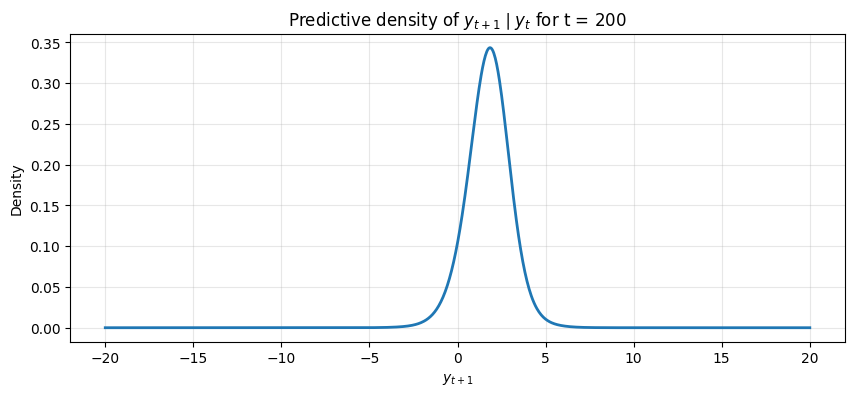

In [144]:

def sample_based_pred_density_marx11(
    t0, y_next, y, X, phi, psi, beta, sigma, nu
):
    y = np.asarray(y, dtype=float)
    X = np.asarray(X, dtype=float)
    y_next = np.asarray(y_next, dtype=float)

    # Current and next exogenous observations
    x_T = X[t0]
    x_next = X[t0 + 1] if t0 + 1 < len(X) else 0.0

    # Current state
    y_T = y[t0]
    y_Tm1 = y[t0 - 1]
    u_T = y_T - phi * y_Tm1

    # Historical states
    u_sample = y[1:t0+1] - phi * y[:t0]

    # Candidate future state
    u_next = y_next - phi * y_T

    # First factor
    term1 = student_t_pdf(
        u_T - psi * u_next - beta * x_T,
        nu, sigma
    )

    # Numerator
    num = np.sum(
        student_t_pdf(
            u_next[:, None]
            - psi * u_sample[None, :]
            - beta * x_next,
            nu, sigma
        ),
        axis=1
    )

    # Denominator
    den = np.sum(
        student_t_pdf(
            u_T - psi * u_sample - beta * x_T,
            nu, sigma
        )
    )
    den = max(den, 1e-12)

    return term1 * (num / den)



grid = np.linspace(-20, 20, 1000)

# point for which we calculate predictive density
t0 = 199

dens = sample_based_pred_density_marx11(t0, grid, y, X, phi_hat, psi_hat, beta_hat, sigma_hat, nu_hat)

# normalization
area = integrate_area(dens, grid)
if area > 0 and np.isfinite(area):
    dens = dens / area

# Plot
plt.figure(figsize=(10, 4))
plt.plot(grid, dens, lw=2)
plt.title(rf"Predictive density of $y_{{t+1}}\mid y_t$ for t = {t0 + 1}")
plt.xlabel(r"$y_{t+1}$")
plt.ylabel("Density")
plt.grid(True, alpha=0.3)
plt.show()


### Bimodality Measure

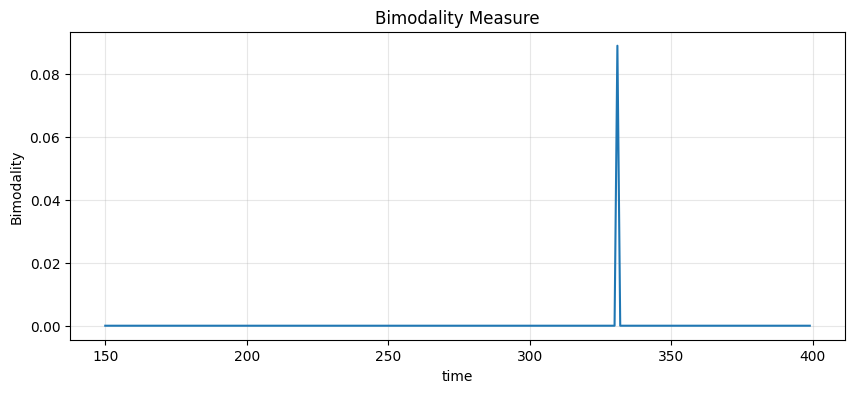

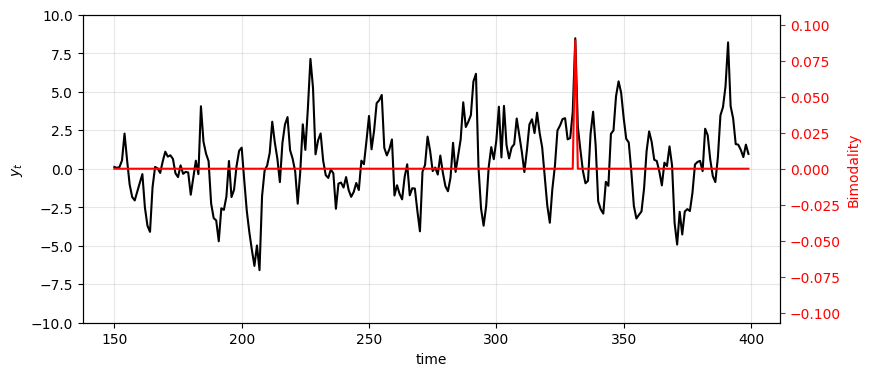

In [145]:
start_t = max(1, T - H)
end_t = T
times = np.arange(start_t, end_t)

bimodality_series = compute_bimodality_series(
    times,
    predictive_density_fn=sample_based_pred_density_marx11,
    y=y,
    X=X,
    phi=phi_hat,
    psi=psi_hat,
    beta=beta_hat,
    sigma=sigma_hat,
    nu=nu_hat,
    grid_min=-20,
    grid_max=20,
    n_grid= 1000
)

plot_bimodality(times, bimodality_series)

plot_bimodality_and_series(
    times,
    y[start_t:end_t],
    bimodality_series,
    y_limits=(-10, 10)
)